# 🎄 Santa 2025: Reinforcement Learning ile Ağaç Paketleme

Bu notebook, Santa 2025 yarışması için geliştirdiğimiz RL tabanlı çözümün teorik ve pratik yönlerini kapsar.

## İçindekiler
1. [Reinforcement Learning Temelleri](#1-reinforcement-learning-temelleri)
2. [Problem Tanımı ve MDP Formülasyonu](#2-problem-tanımı-ve-mdp-formülasyonu)
3. [Environment Mimarisi](#3-environment-mimarisi)
4. [Neural Network Mimarisi](#4-neural-network-mimarisi)
5. [PPO Algoritması](#5-ppo-algoritması)
6. [Training Loop](#6-training-loop)
7. [Çalıştırma ve Görselleştirme](#7-çalıştırma-ve-görselleştirme)

## Setup

In [1]:
import sys
sys.path.append('../training')

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Kendi modüllerimiz
from environment import TreePackingEnvironment, ChristmasTree, scale_factor
from networks import ActorCritic, create_network, obs_to_tensor
from utils import find_nearest_neighbours, get_pairwise_rotated_rects

print('✅ Tüm modüller yüklendi')

✅ Tüm modüller yüklendi


---
# 1. Reinforcement Learning Temelleri

## 1.1 RL Nedir?

Reinforcement Learning (Pekiştirmeli Öğrenme), bir **agent**'ın bir **environment** ile etkileşerek **reward** maksimize etmeyi öğrendiği bir makine öğrenmesi paradigmasıdır.

```
┌─────────────────────────────────────────────────────────┐
│                                                         │
│    ┌─────────┐                    ┌─────────────────┐   │
│    │  Agent  │ ──── action ────►  │   Environment   │   │
│    │ (Policy)│ ◄── reward ─────   │  (Tree Packing) │   │
│    │         │ ◄── state ──────   │                 │   │
│    └─────────┘                    └─────────────────┘   │
│                                                         │
└─────────────────────────────────────────────────────────┘
```

## 1.2 Temel Kavramlar

| Kavram | Sembol | Açıklama | Bizim Problemde |
|--------|--------|----------|----------------|
| **State** | $s$ | Environment'ın mevcut durumu | Yerleştirilmiş ağaçların özellikleri |
| **Action** | $a$ | Agent'ın aldığı karar | $(x, y, \theta)$ - ağaç konumu ve rotasyonu |
| **Reward** | $r$ | Aksiyonun sonucunun kalitesi | BBox büyümesi, çarpışma, kompaktlık |
| **Policy** | $\pi(a|s)$ | State → Action maplemesi | Neural Network |
| **Value** | $V(s)$ | State'in uzun vadeli değeri | Critic network |

## 1.3 Markov Decision Process (MDP)

RL problemleri MDP olarak formüle edilir:

$$MDP = (S, A, P, R, \gamma)$$

- $S$: State space (tüm olası durumlar)
- $A$: Action space (tüm olası aksiyonlar)
- $P(s'|s,a)$: Geçiş olasılıkları
- $R(s,a,s')$: Reward fonksiyonu
- $\gamma$: Discount factor (0-1)

---
# 2. Problem Tanımı ve MDP Formülasyonu

## 2.1 Santa 2025 Problemi

**Amaç:** $N$ adet Noel ağacını minimum kare bounding box içine sığdırmak.

**Kısıtlar:**
- Ağaçlar çakışamaz (touching OK, intersecting NOT OK)
- Her ağaç 0-360° arasında döndürülebilir
- Skor = $1 / \text{kenar uzunluğu}$ (maksimize edilmeli)

## 2.2 MDP Formülasyonu

### State Space $S$
```python
state = {
    "tree_features": (max_trees, 10),      # Her ağacın özellikleri
    "pairwise_features": (max_trees, 10),  # Komşuluk özellikleri
    "scalars": (5,),                        # Global özellikler
    "mask": (max_trees,)                    # Hangi slot'lar dolu
}
```

### Action Space $A$
```python
action = [x, y, rotation]  # Continuous: [-20, 20] × [-20, 20] × [0, 360]
```

### Reward Function $R$

In [2]:
# Reward fonksiyonumuzun bileşenleri (güncellenmiş):

reward_components = {
    "Çarpışma Cezası": "min(collision_area / avg_tree_area × 10, 5.0)",
    "BBox Genişleme": "min((new_area - old_area) / old_area × 5, 3.0)",
    "BBox Sabit/Küçülme": "+2.0 (kutu büyümezse)",
    "Fill Ratio Bonus": "fill_ratio × 1.0 (max +1.0)",
    "Kompaktlık Bonus": "(1 - rect_union/bbox) × 1.0 (max +1.0)",
    "Centroid Stability": "(1 - normalized_shift) × 0.5 (NEW!)",
    "Episode Sonu": "-log(bbox_size_normalized) (logarithmic)",
}

print("📊 Reward Fonksiyonu Bileşenleri (Güncellenmiş):")
print("=" * 55)
for name, formula in reward_components.items():
    print(f"{name:22} → {formula}")

📊 Reward Fonksiyonu Bileşenleri (Güncellenmiş):
Çarpışma Cezası        → min(collision_area / avg_tree_area × 10, 5.0)
BBox Genişleme         → min((new_area - old_area) / old_area × 5, 3.0)
BBox Sabit/Küçülme     → +2.0 (kutu büyümezse)
Fill Ratio Bonus       → fill_ratio × 1.0 (max +1.0)
Kompaktlık Bonus       → (1 - rect_union/bbox) × 1.0 (max +1.0)
Centroid Stability     → (1 - normalized_shift) × 0.5 (NEW!)
Episode Sonu           → -log(bbox_size_normalized) (logarithmic)


---
# 3. Environment Mimarisi

## 3.1 Environment Sınıfı

In [3]:
# Environment'ı oluşturalım
env = TreePackingEnvironment(n_trees=5, max_trees=200)

print("🌲 TreePackingEnvironment")
print("=" * 50)
print(f"Action Space: {env.action_space}")
print(f"Observation Space keys: {list(env.observation_space.spaces.keys())}")
print(f"\nObservation shapes:")
for key, space in env.observation_space.spaces.items():
    print(f"  {key}: {space.shape}")

🌲 TreePackingEnvironment
Action Space: Box([-20. -20.   0.], [ 20.  20. 360.], (3,), float32)
Observation Space keys: ['mask', 'pairwise_features', 'scalars', 'tree_features']

Observation shapes:
  mask: (200,)
  pairwise_features: (200, 10)
  scalars: (5,)
  tree_features: (200, 10)


## 3.2 Christmas Tree Geometrisi

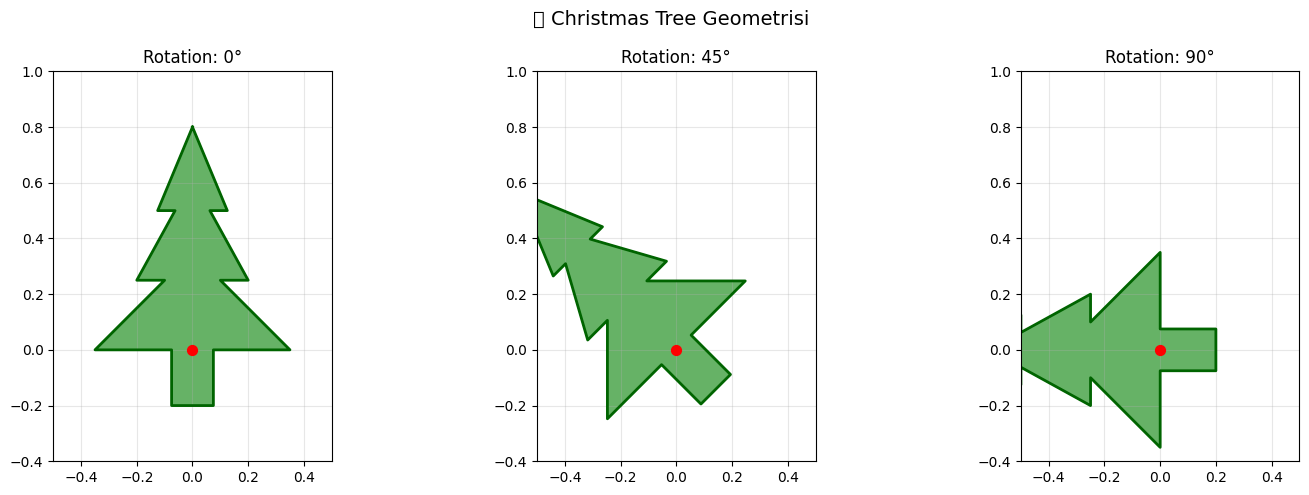


Ağaç Özellikleri:
  Area: 0.2456
  Bounds: [-0.8  -0.35  0.2   0.35]


In [4]:
# Tek bir ağaç görselleştirelim
tree = ChristmasTree(center_x='0', center_y='0', angle='0')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

norm = float(scale_factor)

# Farklı açılarda ağaçlar
for i, angle in enumerate([0, 45, 90]):
    ax = axes[i]
    tree = ChristmasTree(center_x='0', center_y='0', angle=str(angle))
    
    coords = np.array(tree.polygon.exterior.coords) / norm
    ax.fill(coords[:, 0], coords[:, 1], alpha=0.6, color='green')
    ax.plot(coords[:, 0], coords[:, 1], color='darkgreen', linewidth=2)
    ax.scatter([0], [0], color='red', s=50, zorder=5, label='Center')
    
    ax.set_title(f'Rotation: {angle}°')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-0.5, 0.5)
    ax.set_ylim(-0.4, 1.0)

plt.suptitle('🎄 Christmas Tree Geometrisi', fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nAğaç Özellikleri:")
print(f"  Area: {tree.polygon.area / norm**2:.4f}")
bounds = np.array(tree.polygon.bounds) / norm
print(f"  Bounds: {bounds}")

## 3.3 Environment Step Örneği

📋 Initial State:
  n_placed: 0
  mask sum: 0.0

📍 Steps:
------------------------------------------------------------
Step 1: action=[0.0, 0.0, 0]
         reward=1.246, collision=False, trees=1
Step 2: action=[1.0, 0.0, 45]
         reward=-2.320, collision=False, trees=2
Step 3: action=[0.5, 1.0, 90]
         reward=2.737, collision=False, trees=3


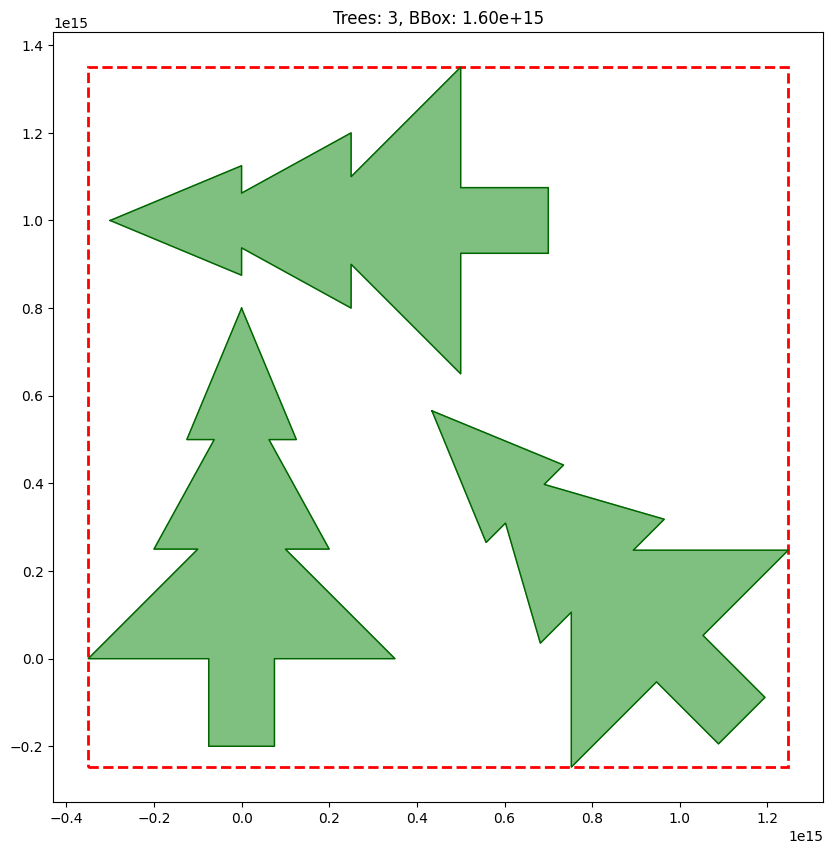

In [5]:
# Environment'ı sıfırla ve step'leri göster
env = TreePackingEnvironment(n_trees=5)
obs, info = env.reset()

print("📋 Initial State:")
print(f"  n_placed: {info['n_placed']}")
print(f"  mask sum: {obs['mask'].sum()}")

# Birkaç ağaç yerleştir
actions = [
    [0.0, 0.0, 0],     # Merkeze
    [1.0, 0.0, 45],    # Sağa, 45° dönmüş
    [0.5, 1.0, 90],    # Yukarıya, 90° dönmüş
]

print("\n📍 Steps:")
print("-" * 60)

for i, action in enumerate(actions):
    obs, reward, done, truncated, info = env.step(np.array(action, dtype=np.float32))
    print(f"Step {i+1}: action={action}")
    print(f"         reward={reward:.3f}, collision={info['collision']}, trees={info['n_placed']}")

# Sonucu görselleştir
env.render()

## 3.4 Observation Dictionary Yapısı

In [6]:
# Observation'ın detayları
obs = env.get_observation()

print("🔍 Observation Dictionary:")
print("=" * 60)

# Tree features
print("\n1️⃣ tree_features (max_trees, 10):")
print("   [x, y, angle, minx, miny, maxx, maxy, width, height, area]")
print(f"   Shape: {obs['tree_features'].shape}")
print(f"   First tree: {obs['tree_features'][0][:5]}...")

# Pairwise features
print("\n2️⃣ pairwise_features (max_trees, 10):")
print("   [distance, dx, dy, pair_minx, pair_miny, pair_maxx, pair_maxy, pair_w, pair_h, neighbor_idx]")
print(f"   Shape: {obs['pairwise_features'].shape}")

# Scalars
print("\n3️⃣ scalars (5,):")
print("   [n_placed_norm, bbox_size_norm, fill_ratio, remaining_ratio, total_area_norm]")
print(f"   Values: {obs['scalars']}")

# Mask
print("\n4️⃣ mask (max_trees,):")
print(f"   Sum (placed trees): {obs['mask'].sum()}")

🔍 Observation Dictionary:

1️⃣ tree_features (max_trees, 10):
   [x, y, angle, minx, miny, maxx, maxy, width, height, area]
   Shape: (200, 10)
   First tree: [ 0.    0.    0.   -0.35 -0.2 ]...

2️⃣ pairwise_features (max_trees, 10):
   [distance, dx, dy, pair_minx, pair_miny, pair_maxx, pair_maxy, pair_w, pair_h, neighbor_idx]
   Shape: (200, 10)

3️⃣ scalars (5,):
   [n_placed_norm, bbox_size_norm, fill_ratio, remaining_ratio, total_area_norm]
   Values: [0.015      0.15974873 0.28874797 0.4        0.736875  ]

4️⃣ mask (max_trees,):
   Sum (placed trees): 3.0


---
# 4. Neural Network Mimarisi

## 4.1 Genel Mimari

In [7]:
architecture_diagram = """
┌─────────────────────────────────────────────────────────────────────────┐
│                        ACTOR-CRITIC NETWORK                             │
├─────────────────────────────────────────────────────────────────────────┤
│                                                                         │
│  INPUT LAYER                                                            │
│  ───────────                                                            │
│  tree_features (200×10) ──► TreeFeatureEncoder ──► (200×64)  ─┐        │
│                                                                │        │
│  pairwise_features (200×10) ► PairwiseEncoder ──► (200×64)  ──┼─► CAT  │
│                                                                │   │    │
│                                                         (200×128)  │    │
│                                                                    ▼    │
│  TRANSFORMER ENCODER                                                    │
│  ───────────────────                                                    │
│  ┌────────────────────────────────────────┐                             │
│  │  4-head Self-Attention                 │                             │
│  │  × 2 layers                            │                             │
│  │  + Masked Mean Pooling                 │                             │
│  └────────────────────────────────────────┘                             │
│                        │                                                │
│                        ▼                                                │
│                    (batch, 256)                                         │
│                        │                                                │
│  scalars (5) ──► ScalarEncoder ──► (32) ──┼──► CONCAT                  │
│                                            │                            │
│                                     (batch, 288)                        │
│                                            │                            │
│  OUTPUT HEADS                              │                            │
│  ────────────                    ┌─────────┴─────────┐                  │
│                                  │                   │                  │
│                           ┌──────▼──────┐    ┌───────▼──────┐          │
│                           │    ACTOR    │    │    CRITIC    │          │
│                           │  MLP (128)  │    │   MLP (128)  │          │
│                           └──────┬──────┘    └───────┬──────┘          │
│                                  │                   │                  │
│                           mean, log_std          value                  │
│                              (3, 3)               (1)                   │
│                                                                         │
└─────────────────────────────────────────────────────────────────────────┘
"""

print(architecture_diagram)


┌─────────────────────────────────────────────────────────────────────────┐
│                        ACTOR-CRITIC NETWORK                             │
├─────────────────────────────────────────────────────────────────────────┤
│                                                                         │
│  INPUT LAYER                                                            │
│  ───────────                                                            │
│  tree_features (200×10) ──► TreeFeatureEncoder ──► (200×64)  ─┐        │
│                                                                │        │
│  pairwise_features (200×10) ► PairwiseEncoder ──► (200×64)  ──┼─► CAT  │
│                                                                │   │    │
│                                                         (200×128)  │    │
│                                                                    ▼    │
│  TRANSFORMER ENCODER                                                    │
│  ──────────

## 4.2 Network Parametreleri

In [8]:
# Network oluştur
network = create_network()

# Parametre sayısı
total_params = sum(p.numel() for p in network.parameters())
trainable_params = sum(p.numel() for p in network.parameters() if p.requires_grad)

print("🧠 Network Parametreleri:")
print("=" * 50)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print("\n📦 Module bazında:")
for name, module in network.named_children():
    params = sum(p.numel() for p in module.parameters())
    print(f"  {name}: {params:,}")

🧠 Network Parametreleri:
Total parameters: 543,047
Trainable parameters: 543,047

📦 Module bazında:
  tree_encoder: 2,464
  pairwise_encoder: 2,464
  transformer: 429,568
  scalar_encoder: 640
  actor: 54,278
  critic: 53,633


## 4.3 Forward Pass Örneği

In [9]:
# Örnek observation
obs = env.get_observation()
obs_tensor = obs_to_tensor(obs)

print("📥 Input shapes:")
for k, v in obs_tensor.items():
    print(f"  {k}: {v.shape}")

# Forward pass
with torch.no_grad():
    mean, log_std, value = network(obs_tensor)

print("\n📤 Output shapes:")
print(f"  mean (action): {mean.shape} → {mean.squeeze().numpy()}")
print(f"  log_std:       {log_std.shape} → {log_std.squeeze().numpy()}")
print(f"  value:         {value.shape} → {value.item():.4f}")
# Action sampling
action, log_prob, value = network.get_action(obs_tensor)
print(f"\n🎯 Sampled action: {action.squeeze().detach().numpy()}")
print(f"   Log probability: {log_prob.item():.4f}")

📥 Input shapes:
  tree_features: torch.Size([1, 200, 10])
  pairwise_features: torch.Size([1, 200, 10])
  scalars: torch.Size([1, 5])
  mask: torch.Size([1, 200])

📤 Output shapes:
  mean (action): torch.Size([1, 3]) → [-0.12722415  0.0914335  -0.01382485]
  log_std:       torch.Size([1, 3]) → [ 0.08384071  0.08997256 -0.03766856]
  value:         torch.Size([1, 1]) → -0.0167

🎯 Sampled action: [-15.271198  17.229538 206.9298  ]
   Log probability: -12.8040


## 4.4 Gaussian Policy

Actor network bir **Gaussian (Normal) dağılım** parametreleri üretir:

$$\pi(a|s) = \mathcal{N}(\mu(s), \sigma(s)^2)$$

Burada:
- $\mu(s)$: State\'e bağlı mean (neural network çıktısı)
- $\sigma(s)$: **State-dependent** standard deviation (log_std_head\'den)

> **Not:** Eski implementasyonda σ global bir parametreydi. Yeni versiyonda
> state-dependent std kullanılıyor (daha iyi exploration).

### Action Squashing (Tanh)

Continuous action'lar bounds içinde kalmak için tanh ile squash edilir:

$$a_{bounded} = \tanh(a_{raw}) \cdot scale + bias$$

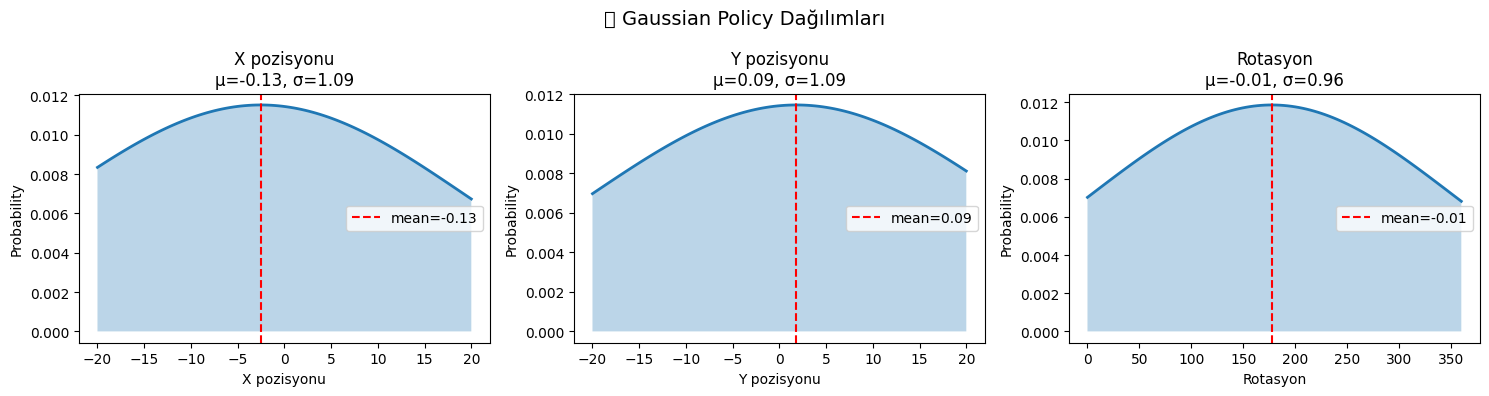

In [10]:
# Gaussian policy görselleştirme
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

action_names = ['X pozisyonu', 'Y pozisyonu', 'Rotasyon']
action_bounds = [(-20, 20), (-20, 20), (0, 360)]

mean_np = mean.squeeze().numpy()
std_np = np.exp(log_std.squeeze().numpy())

for i, (ax, name, bounds) in enumerate(zip(axes, action_names, action_bounds)):
    x = np.linspace(bounds[0], bounds[1], 100)
    
    # Tanh transformation
    scale = (bounds[1] - bounds[0]) / 2
    bias = (bounds[1] + bounds[0]) / 2
    
    # Approximate distribution after tanh
    pdf = np.exp(-0.5 * ((x - (np.tanh(mean_np[i]) * scale + bias)) / (std_np[i] * scale))**2)
    pdf /= pdf.sum()
    
    ax.fill_between(x, pdf, alpha=0.3)
    ax.plot(x, pdf, linewidth=2)
    ax.axvline(np.tanh(mean_np[i]) * scale + bias, color='red', linestyle='--', label=f'mean={mean_np[i]:.2f}')
    ax.set_xlabel(name)
    ax.set_ylabel('Probability')
    ax.set_title(f'{name}\nμ={mean_np[i]:.2f}, σ={std_np[i]:.2f}')
    ax.legend()

plt.suptitle('🎯 Gaussian Policy Dağılımları', fontsize=14)
plt.tight_layout()
plt.show()

---
# 5. PPO Algoritması

## 5.1 Policy Gradient Temelleri

Hedef: Expected return'ü maksimize et:

$$J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta}\left[\sum_{t=0}^T \gamma^t r_t\right]$$

Policy Gradient Teoremi:

$$\nabla_\theta J(\theta) = \mathbb{E}\left[\nabla_\theta \log \pi_\theta(a|s) \cdot A(s, a)\right]$$

## 5.2 PPO Clipped Objective

PPO, policy update'leri sınırlandırarak stabil öğrenme sağlar:

$$L^{CLIP}(\theta) = \mathbb{E}\left[\min\left(r_t(\theta) A_t, \text{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon) A_t\right)\right]$$

Burada:
- $r_t(\theta) = \frac{\pi_\theta(a_t|s_t)}{\pi_{\theta_{old}}(a_t|s_t)}$ (probability ratio)
- $\epsilon$ = 0.2 (clip range)
- $A_t$ = advantage function

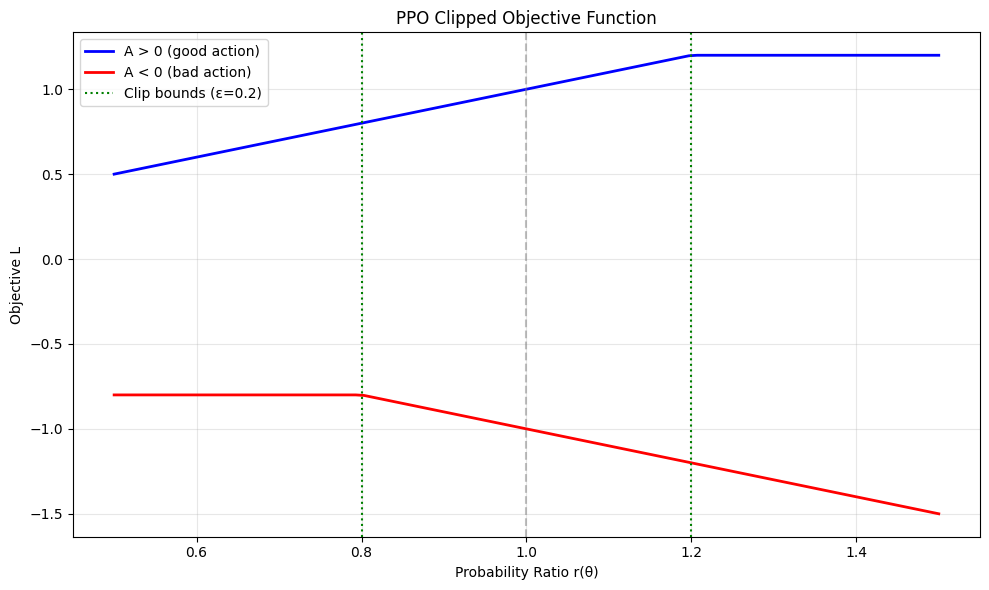

In [11]:
# PPO Clip görselleştirme
fig, ax = plt.subplots(figsize=(10, 6))

ratios = np.linspace(0.5, 1.5, 100)
epsilon = 0.2

# Advantage > 0 durumu
advantage_pos = 1.0
surr1_pos = ratios * advantage_pos
surr2_pos = np.clip(ratios, 1-epsilon, 1+epsilon) * advantage_pos
objective_pos = np.minimum(surr1_pos, surr2_pos)

# Advantage < 0 durumu
advantage_neg = -1.0
surr1_neg = ratios * advantage_neg
surr2_neg = np.clip(ratios, 1-epsilon, 1+epsilon) * advantage_neg
objective_neg = np.minimum(surr1_neg, surr2_neg)

ax.plot(ratios, objective_pos, 'b-', linewidth=2, label='A > 0 (good action)')
ax.plot(ratios, objective_neg, 'r-', linewidth=2, label='A < 0 (bad action)')
ax.axvline(1, color='gray', linestyle='--', alpha=0.5)
ax.axvline(1-epsilon, color='green', linestyle=':', label=f'Clip bounds (ε={epsilon})')
ax.axvline(1+epsilon, color='green', linestyle=':')

ax.set_xlabel('Probability Ratio r(θ)')
ax.set_ylabel('Objective L')
ax.set_title('PPO Clipped Objective Function')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5.3 Generalized Advantage Estimation (GAE)

Advantage function'ı hesaplamak için GAE kullanırız:

$$\hat{A}_t = \sum_{l=0}^{\infty} (\gamma \lambda)^l \delta_{t+l}$$

Burada:
$$\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$$

GAE, bias-variance trade-off yaparak daha stabil advantage tahminleri sağlar.

In [12]:
# GAE hesaplama örneği
def compute_gae(rewards, values, dones, gamma=0.99, gae_lambda=0.95):
    """GAE ile advantage ve returns hesapla."""
    n = len(rewards)
    advantages = np.zeros(n)
    last_gae = 0
    
    for t in reversed(range(n)):
        if t == n - 1:
            next_value = 0
        else:
            next_value = values[t + 1]
        
        # TD error
        delta = rewards[t] + gamma * next_value * (1 - dones[t]) - values[t]
        
        # GAE
        advantages[t] = last_gae = delta + gamma * gae_lambda * (1 - dones[t]) * last_gae
    
    returns = advantages + values
    return returns, advantages

# Örnek
rewards = [1.0, -0.5, 2.0, -1.0, 3.0]
values = [0.5, 0.3, 0.8, 0.2, 1.0]
dones = [0, 0, 0, 0, 1]

returns, advantages = compute_gae(rewards, np.array(values), np.array(dones))

print("GAE Hesaplama Örneği:")
print("=" * 50)
print(f"Rewards:    {rewards}")
print(f"Values:     {values}")
print(f"Returns:    {returns.round(3)}")
print(f"Advantages: {advantages.round(3)}")

GAE Hesaplama Örneği:
Rewards:    [1.0, -0.5, 2.0, -1.0, 3.0]
Values:     [0.5, 0.3, 0.8, 0.2, 1.0]
Returns:    [3.916 3.085 3.77  1.871 3.   ]
Advantages: [3.416 2.785 2.97  1.671 2.   ]


---
# 6. Training Loop

## 6.1 PPO Training Döngüsü

In [13]:
training_loop_pseudocode = """
PPO Training Loop:
─────────────────────────────────────────────────────

for episode in range(n_episodes):
    
    # 1. Rollout Collection
    ──────────────────────
    buffer = []
    obs = env.reset()
    
    for step in range(n_steps):
        action, log_prob, value = network.get_action(obs)
        next_obs, reward, done, info = env.step(action)
        buffer.add(obs, action, reward, value, log_prob, done)
        obs = next_obs
    
    # 2. Compute Returns and Advantages (GAE)
    ─────────────────────────────────────────
    returns, advantages = compute_gae(buffer.rewards, buffer.values)
    advantages = (advantages - mean) / std  # Normalize
    
    # 3. PPO Update
    ───────────────
    for epoch in range(n_epochs):
        for batch in buffer.sample_batches():
            
            # Evaluate actions
            new_log_prob, value, entropy = network.evaluate(batch.obs, batch.action)
            
            # Policy loss (clipped)
            ratio = exp(new_log_prob - old_log_prob)
            surr1 = ratio * advantages
            surr2 = clip(ratio, 1-ε, 1+ε) * advantages
            policy_loss = -min(surr1, surr2).mean()
            
            # Value loss
            value_loss = MSE(value, returns)
            
            # Entropy bonus (exploration)
            entropy_loss = -entropy.mean()
            
            # Total loss
            loss = policy_loss + 0.5 * value_loss + 0.01 * entropy_loss
            
            # Optimize
            optimizer.zero_grad()
            loss.backward()
            clip_grad_norm(network.parameters(), 0.5)
            optimizer.step()
"""

print(training_loop_pseudocode)


PPO Training Loop:
─────────────────────────────────────────────────────

for episode in range(n_episodes):

    # 1. Rollout Collection
    ──────────────────────
    buffer = []
    obs = env.reset()

    for step in range(n_steps):
        action, log_prob, value = network.get_action(obs)
        next_obs, reward, done, info = env.step(action)
        buffer.add(obs, action, reward, value, log_prob, done)
        obs = next_obs

    # 2. Compute Returns and Advantages (GAE)
    ─────────────────────────────────────────
    returns, advantages = compute_gae(buffer.rewards, buffer.values)
    advantages = (advantages - mean) / std  # Normalize

    # 3. PPO Update
    ───────────────
    for epoch in range(n_epochs):
        for batch in buffer.sample_batches():

            # Evaluate actions
            new_log_prob, value, entropy = network.evaluate(batch.obs, batch.action)

            # Policy loss (clipped)
            ratio = exp(new_log_prob - old_log_prob)
            surr1 

## 6.2 Hyperparametreler

In [14]:
hyperparams = {
    "Learning Rate (lr)": "3e-4",
    "Discount Factor (γ)": "0.99",
    "GAE Lambda (λ)": "0.95",
    "Clip Epsilon (ε)": "0.2",
    "Entropy Coefficient": "0.05 (artırıldı)",
    "Value Coefficient": "0.5",
    "Max Grad Norm": "0.5",
    "PPO Epochs": "4",
    "Batch Size": "32",
    "Visualization": "Async (file-based)",
}

print("⚙️ Default Hyperparametreler:")
print("=" * 50)
for name, value in hyperparams.items():
    print(f"  {name:25} = {value}")

⚙️ Default Hyperparametreler:
  Learning Rate (lr)        = 3e-4
  Discount Factor (γ)       = 0.99
  GAE Lambda (λ)            = 0.95
  Clip Epsilon (ε)          = 0.2
  Entropy Coefficient       = 0.05 (artırıldı)
  Value Coefficient         = 0.5
  Max Grad Norm             = 0.5
  PPO Epochs                = 4
  Batch Size                = 32
  Visualization             = Async (file-based)


---
# 7. Çalıştırma ve Görselleştirme

## 7.1 Kısa Bir Training Demosu

In [15]:
from training import PPOTrainer

# Kısa bir training (görselleştirme kapalı)
trainer = PPOTrainer(
    n_trees=5,
    lr=3e-4,
    n_epochs=4,
    batch_size=32,
    visualize=False  # Notebook için kapalı
)

print("🚀 Training başlıyor (20 episode)...")
print("=" * 50)

rewards_log = []
bbox_log = []

for episode in range(20):
    # Collect rollout
    episode_reward, bbox_size = trainer.collect_rollouts(trainer.n_trees)
    rewards_log.append(episode_reward)
    bbox_log.append(bbox_size / float(scale_factor))
    
    # Compute returns
    with torch.no_grad():
        obs = trainer.env.get_observation()
        obs_tensor = {k: torch.tensor(v, dtype=torch.float32, device=trainer.device).unsqueeze(0) for k, v in obs.items()}
        _, _, last_value = trainer.network.forward(obs_tensor)
        last_value = last_value.item()
    
    returns, advantages = trainer.buffer.compute_returns_and_advantages(last_value)
    
    # Update
    trainer.update(returns, advantages)
    trainer.buffer.clear()
    
    if (episode + 1) % 5 == 0:
        print(f"Episode {episode+1:3d} | Reward: {episode_reward:8.2f} | BBox: {bbox_size/float(scale_factor):.4f}")

print("\n✅ Training tamamlandı!")

Using device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti
CUDA Version: 12.8
🚀 Training başlıyor (20 episode)...
Episode   5 | Reward:    -7.09 | BBox: 39.5158
Episode  10 | Reward:    -6.83 | BBox: 36.6803
Episode  15 | Reward:    -6.90 | BBox: 33.5271
Episode  20 | Reward:    -4.46 | BBox: 40.8932

✅ Training tamamlandı!


## 7.2 Training Metrikleri

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Reward curve
axes[0].plot(rewards_log, 'b-', linewidth=2)
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Episode Reward')
axes[0].set_title('🏆 Training Reward Curve')
axes[0].grid(True, alpha=0.3)

# BBox size curve
axes[1].plot(bbox_log, 'r-', linewidth=2)
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('BBox Size (normalized)')
axes[1].set_title('📦 Bounding Box Size')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n📊 Sonuçlar:")
print(f"  İlk 5 episode ortalama reward: {np.mean(rewards_log[:5]):.2f}")
print(f"  Son 5 episode ortalama reward: {np.mean(rewards_log[-5:]):.2f}")
print(f"  İyileşme: {np.mean(rewards_log[-5:]) - np.mean(rewards_log[:5]):.2f}")


📊 Sonuçlar:
  İlk 5 episode ortalama reward: -0.02
  Son 5 episode ortalama reward: -1.83
  İyileşme: -1.81


## 7.3 Son Yerleştirmeyi Görselleştir

In [17]:
# Son episode'u görselleştir
env = TreePackingEnvironment(n_trees=10)
obs, _ = env.reset()

# Trained policy ile yerleştir
for step in range(10):
    obs_tensor = obs_to_tensor(obs, device=trainer.device)
    with torch.no_grad():
        action, _, _ = trainer.network.get_action(obs_tensor, deterministic=True)
    action_np = action.squeeze().cpu().numpy()
    obs, reward, done, _, info = env.step(action_np)
    if done:
        break

# Görselleştir
env.render()

print(f"\n📊 Sonuç:")
print(f"  Yerleştirilen ağaç: {len(env.placed_trees)}")
print(f"  BBox size: {env.bounding_box_size / float(scale_factor):.4f}")
print(f"  Fill ratio: {env.fill_ratio:.4f}")


📊 Sonuç:
  Yerleştirilen ağaç: 7
  BBox size: 10.5669
  Fill ratio: 0.0154


---
## 🎓 Özet

Bu notebook'ta öğrendiklerimiz:

1. **RL Temelleri**: MDP, policy, value, reward kavramları
2. **Problem Formülasyonu**: State/Action/Reward tasarımı
3. **Environment**: Shapely tabanlı geometrik environment
4. **Neural Network**: Transformer-based Actor-Critic
5. **PPO Algoritması**: Clipped objective, GAE
6. **Training**: Rollout collection, policy update

### Sonraki Adımlar:
- [ ] Hyperparameter tuning
- [ ] Daha uzun training
- [ ] Model checkpointing
- [ ] Evaluation ve submission